# **Nama : Ahmat Pratoga Sembiring**
# **NIM : 123140053**
# **Tugas Pembelajaran Mendalam - Spesifikasi	Tugas	Studio	Proyek	1**

# Spesifikasi Tugas Studio Proyek 1
## Fine-Tuning ANN (from scratch) pada CIFAR-10 Dataset



---

### Tujuan Proyek

Proyek ini bertujuan untuk membangun dan melakukan fine-tuning
Artificial Neural Network (ANN) dari scratch menggunakan PyTorch
untuk melakukan klasifikasi citra pada dataset CIFAR-10.

Eksperimen dilakukan secara sistematis dengan membandingkan
optimizer, scheduler, regularisasi, serta kapasitas arsitektur
model untuk memperoleh strategi pelatihan yang paling efektif
berdasarkan hasil eksperimen.

---
## 0. Setup & Konfigurasi Awal

Pada bagian ini dilakukan import library yang akan digunakan selama proses pengerjaan. Selain itu, random seed diatur agar hasil eksperimen dapat dibuat lebih konsisten ketika notebook
dijalankan kembali.


In [1]:
import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
import torchvision
import torchvision.transforms as transforms

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

sns.set_theme(style="whitegrid")
print("PyTorch version:", torch.__version__)


PyTorch version: 2.11.0+cpu


In [2]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Menggunakan device:", DEVICE)

# Folder untuk menyimpan checkpoint model terbaik (poin C.4 - Model Checkpointing)
CKPT_DIR = "checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']


Menggunakan device: cpu


---
## 1. Preparation & Preprocessing (poin C.1)

- Dataset CIFAR-10 diambil menggunakan `torchvision.datasets`.
-  Karena
model yang digunakan berupa ANN/MLP, gambar 32×32×3 di- flatten menjadi vektor berukuran 3072.
- Diterapkan augmentasi dasar pada data latih (`RandomCrop`, `RandomHorizontalFlip`) untuk membantu generalisasi, sesuai capaian pembelajaran poin B.4.
- Data latih asli (50.000 gambar) dibagi lagi menjadi train/validation split agar Early Stopping (poin C.4) punya sinyal validasi yang independen dari test set.


In [3]:
# Statistik normalisasi standar CIFAR-10
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

# Transform untuk data TRAIN -> augmentasi + flatten
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
    transforms.Lambda(lambda x: torch.flatten(x))
])

# Transform untuk data VAL/TEST -> tanpa augmentasi, hanya flatten
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
    transforms.Lambda(lambda x: torch.flatten(x))
])


In [4]:
# Unduh dataset CIFAR-10
DATA_ROOT = "./data"

full_train_raw = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True,
                                                download=True, transform=train_transform)
full_train_eval = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True,
                                                 download=True, transform=eval_transform)
test_dataset = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=False,
                                              download=True, transform=eval_transform)

print("Jumlah data train+val (total):", len(full_train_raw))
print("Jumlah data test:", len(test_dataset))


100%|██████████| 170M/170M [43:55<00:00, 64.7kB/s]


Jumlah data train+val (total): 50000
Jumlah data test: 10000


In [5]:
# Split train (50.000) -> train (45.000) & validation (5.000)
VAL_SIZE = 5000
TRAIN_SIZE = len(full_train_raw) - VAL_SIZE

set_seed()
generator = torch.Generator().manual_seed(SEED)
train_indices, val_indices = random_split(
    range(len(full_train_raw)), [TRAIN_SIZE, VAL_SIZE], generator=generator
)
train_indices = train_indices.indices
val_indices = val_indices.indices

# training dengan augmentasi
train_dataset = torch.utils.data.Subset(full_train_raw, train_indices)
# validation tanpa augmentasi
val_dataset = torch.utils.data.Subset(full_train_eval, val_indices)

print("Train:", len(train_dataset), "| Val:", len(val_dataset), "| Test:", len(test_dataset))


Train: 45000 | Val: 5000 | Test: 10000


In [6]:
BATCH_SIZE = 128

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                           num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                           num_workers=2, pin_memory=True)

# Sanity check bentuk data setelah flatten
xb, yb = next(iter(train_loader))
print("Bentuk batch input :", xb.shape)   # -> [batch, 3072]
print("Bentuk batch label :", yb.shape)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Bentuk batch input : torch.Size([128, 3072])
Bentuk batch label : torch.Size([128])


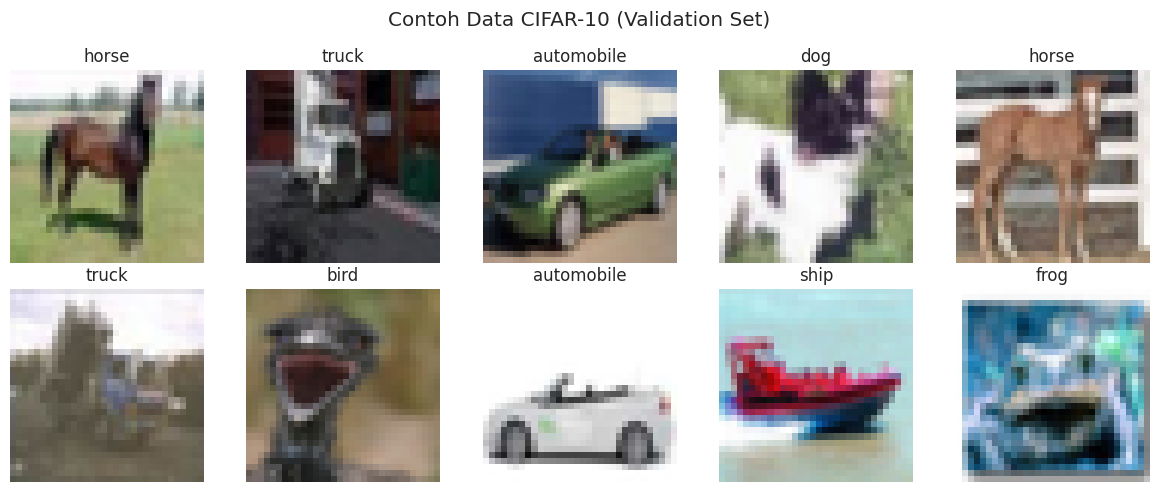

In [7]:
# Visualisasi contoh gambar (sebelum flatten, untuk sanity check visual dataset)
def denormalize(img_flat):
    img = img_flat.view(3, 32, 32).clone()
    for c in range(3):
        img[c] = img[c] * CIFAR_STD[c] + CIFAR_MEAN[c]
    return img.permute(1, 2, 0).clamp(0, 1).numpy()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flatten()):
    img, label = val_dataset[i]
    ax.imshow(denormalize(img))
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")
plt.suptitle("Contoh Data CIFAR-10 (Validation Set)")
plt.tight_layout()
plt.show()


---
## 2. Pembuatan Baseline Model (poin C.2)

Model awal yang digunakan terdiri dari satu input layer dengan
3072 fitur, dua hidden layer, dan output layer dengan 10 neuron.

Arsitektur baseline yang digunakan:

3072 → 256 → 128 → 10

Ukuran hidden layer ini digunakan sebagai konfigurasi awal dan
selanjutnya akan dibandingkan dengan model lain pada eksperimen
kapasitas.


In [8]:
class ANN(nn.Module):
    '''
    Multi-Layer Perceptron (ANN) generik & fleksibel.

    Parameters
    ----------
    input_dim     : dimensi input (3072 untuk CIFAR-10 flatten)
    hidden_dims   : list jumlah neuron tiap hidden layer, mis. [256, 128]
    num_classes   : jumlah kelas output
    dropout_rate  : jika > 0, tambahkan nn.Dropout setelah aktivasi tiap hidden layer
    use_batchnorm : jika True, tambahkan nn.BatchNorm1d setelah setiap Linear (sebelum aktivasi)
    '''
    def __init__(self, input_dim=3072, hidden_dims=(256, 128), num_classes=10,
                 dropout_rate=0.0, use_batchnorm=False):
        super().__init__()
        layers = []
        in_dim = input_dim
        for h in hidden_dims:
            layers.append(nn.Linear(in_dim, h))
            if use_batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU(inplace=True))
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            in_dim = h
        layers.append(nn.Linear(in_dim, num_classes))
        self.net = nn.Sequential(*layers)

        # simpan konfigurasi
        self.config = dict(input_dim=input_dim, hidden_dims=list(hidden_dims),
                            num_classes=num_classes, dropout_rate=dropout_rate,
                            use_batchnorm=use_batchnorm)

    def forward(self, x):
        return self.net(x)

    def __repr_config__(self):
        hd = "-".join(map(str, self.config["hidden_dims"]))
        return f"hidden[{hd}]_drop{self.config['dropout_rate']}_bn{self.config['use_batchnorm']}"


# Baseline: Input(3072) -> Hidden(256) -> Hidden(128) -> Output(10)
baseline_model = ANN(input_dim=3072, hidden_dims=(256, 128), num_classes=10)
print(baseline_model)

n_params = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
print(f"\nTotal trainable parameters (baseline): {n_params:,}")


ANN(
  (net): Sequential(
    (0): Linear(in_features=3072, out_features=256, bias=True)
    (1): ReLU(inplace=True)
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU(inplace=True)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Total trainable parameters (baseline): 820,874


---
## 3. Fungsi Training — Early Stopping & Model Checkpointing (poin C.4)

Fungsi `train_model` di bawah ini mengimplementasikan **from scratch**:
- Loop training standar (forward, loss, backward, optimizer step)
- Evaluasi tiap epoch di validation set
- **Model Checkpointing**: menyimpan (`torch.save`) bobot model setiap kali `val_loss` membaik
- **Early Stopping**: menghentikan training jika `val_loss` tidak membaik selama `patience` epoch berturut-turut
- Mendukung learning-rate `scheduler` opsional (baik yang berbasis epoch seperti `StepLR`, maupun berbasis metric seperti `ReduceLROnPlateau`)


In [9]:
def evaluate(model, loader, criterion, device=DEVICE):
    model.eval()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = criterion(out, yb)
            total_loss += loss.item() * xb.size(0)
            preds = out.argmax(dim=1)
            total_correct += (preds == yb).sum().item()
            total_samples += xb.size(0)
            all_preds.append(preds.cpu())
            all_labels.append(yb.cpu())
    avg_loss = total_loss / total_samples
    avg_acc = total_correct / total_samples
    return avg_loss, avg_acc, torch.cat(all_preds), torch.cat(all_labels)


def train_model(model, train_loader, val_loader, optimizer, criterion=None,
                 scheduler=None, scheduler_type=None, num_epochs=40, patience=6,
                 device=DEVICE, ckpt_name="model", verbose=True):
    '''
    scheduler_type : None | 'epoch' (step tiap epoch, mis. StepLR)
                            | 'plateau' (step berdasarkan val_loss, mis. ReduceLROnPlateau)
    '''
    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    model = model.to(device)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    epochs_no_improve = 0
    ckpt_path = os.path.join(CKPT_DIR, f"{ckpt_name}.pt")

    start_time = time.time()
    for epoch in range(1, num_epochs + 1):
        model.train()
        running_loss, running_correct, running_samples = 0.0, 0, 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * xb.size(0)
            running_correct += (out.argmax(dim=1) == yb).sum().item()
            running_samples += xb.size(0)

        train_loss = running_loss / running_samples
        train_acc = running_correct / running_samples
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, device)

        current_lr = optimizer.param_groups[0]["lr"]
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(current_lr)

        # ---- Scheduler step ----
        if scheduler is not None:
            if scheduler_type == "plateau":
                scheduler.step(val_loss)
            elif scheduler_type == "epoch":
                scheduler.step()

        # ---- Model Checkpointing: simpan jika val_loss membaik ----
        improved = val_loss < best_val_loss - 1e-4
        if improved:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, ckpt_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if verbose:
            print(f"[{ckpt_name}] Epoch {epoch:02d}/{num_epochs} | "
                  f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
                  f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | "
                  f"lr={current_lr:.5f}"
                  + ("  <-- checkpoint saved" if improved else ""))

        # ---- Early Stopping ----
        if epochs_no_improve >= patience:
            if verbose:
                print(f"Early stopping dipicu pada epoch {epoch} "
                      f"(tidak ada perbaikan val_loss selama {patience} epoch).")
            break

    elapsed = time.time() - start_time
    if verbose:
        print(f"Training selesai dalam {elapsed:.1f} detik. Best val_loss={best_val_loss:.4f}")

    # load bobot terbaik sebelum return
    model.load_state_dict(best_state)
    return model, history, elapsed


In [10]:
def plot_history(history, title="Training Curve"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    axes[0].plot(history["train_loss"], label="Train Loss")
    axes[0].plot(history["val_loss"], label="Val Loss")
    axes[0].set_title(f"{title} — Loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(history["train_acc"], label="Train Acc")
    axes[1].plot(history["val_acc"], label="Val Acc")
    axes[1].set_title(f"{title} — Accuracy")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


---
## 4. Training Model Baseline

Melatih arsitektur baseline (2 hidden layer, tanpa regularisasi khusus, optimizer Adam default) sebagai **titik acuan (reference point)** sebelum masuk ke skenario eksperimen. Semua eksperimen berikutnya akan dibandingkan terhadap hasil baseline ini.


In [ ]:
set_seed()
baseline_model = ANN(input_dim=3072, hidden_dims=(256, 128), num_classes=10)
baseline_optimizer = optim.Adam(baseline_model.parameters(), lr=1e-3)

baseline_model, baseline_history, baseline_time = train_model(
    baseline_model, train_loader, val_loader,
    optimizer=baseline_optimizer,
    scheduler=None, scheduler_type=None,
    num_epochs=40, patience=6,
    ckpt_name="baseline"
)

plot_history(baseline_history, title="Baseline ANN (Adam, tanpa scheduler/regularisasi)")

baseline_test_loss, baseline_test_acc, _, _ = evaluate(baseline_model, test_loader, nn.CrossEntropyLoss())
print(f"\nBaseline -> Test Loss: {baseline_test_loss:.4f} | Test Accuracy: {baseline_test_acc:.4f}")


[baseline] Epoch 01/40 | train_loss=1.8142 train_acc=0.3457 | val_loss=1.7093 val_acc=0.3864 | lr=0.00100  <-- checkpoint saved
[baseline] Epoch 02/40 | train_loss=1.6564 train_acc=0.4025 | val_loss=1.6190 val_acc=0.4202 | lr=0.00100  <-- checkpoint saved
[baseline] Epoch 03/40 | train_loss=1.5903 train_acc=0.4297 | val_loss=1.5778 val_acc=0.4360 | lr=0.00100  <-- checkpoint saved
[baseline] Epoch 04/40 | train_loss=1.5442 train_acc=0.4459 | val_loss=1.5524 val_acc=0.4508 | lr=0.00100  <-- checkpoint saved
[baseline] Epoch 05/40 | train_loss=1.5138 train_acc=0.4548 | val_loss=1.5291 val_acc=0.4602 | lr=0.00100  <-- checkpoint saved
[baseline] Epoch 06/40 | train_loss=1.4844 train_acc=0.4678 | val_loss=1.5405 val_acc=0.4544 | lr=0.00100
[baseline] Epoch 07/40 | train_loss=1.4681 train_acc=0.4721 | val_loss=1.5168 val_acc=0.4676 | lr=0.00100  <-- checkpoint saved
[baseline] Epoch 08/40 | train_loss=1.4475 train_acc=0.4787 | val_loss=1.5253 val_acc=0.4726 | lr=0.00100
[baseline] Epoch 09/

### 🔎 Analisis Baseline
_(Isi oleh kelompok)_ Jelaskan: apakah model baseline mengalami overfitting/underfitting? Bagaimana gap antara train accuracy dan val accuracy? Berapa epoch efektif sebelum early stopping berhenti?


---
## 5. Skenario Eksperimen (a): Optimizer & Scheduler (poin C.3.a)

Kita bandingkan kombinasi optimizer & scheduler berikut, dengan arsitektur yang **sama** dengan baseline (agar perbandingan adil / *fair comparison* — hanya optimizer & scheduler yang berubah):

| Nama Eksperimen | Optimizer | Scheduler |
|---|---|---|
| `adam_no_sched` | Adam (lr=1e-3) | - |
| `sgd_momentum_no_sched` | SGD + Momentum (lr=1e-2, momentum=0.9) | - |
| `adam_steplr` | Adam (lr=1e-3) | StepLR (step_size=10, gamma=0.5) |
| `sgd_reduce_on_plateau` | SGD + Momentum (lr=1e-2, momentum=0.9) | ReduceLROnPlateau |

Semua kombinasi memakai arsitektur, jumlah epoch maksimum, dan patience early-stopping yang sama.


In [ ]:
def build_optimizer_scheduler(model, name):
    if name == "adam_no_sched":
        opt = optim.Adam(model.parameters(), lr=1e-3)
        sched, sched_type = None, None
    elif name == "sgd_momentum_no_sched":
        opt = optim.SGD(model.parameters(), lr=1e-2, momentum=0.9)
        sched, sched_type = None, None
    elif name == "adam_steplr":
        opt = optim.Adam(model.parameters(), lr=1e-3)
        sched = optim.lr_scheduler.StepLR(opt, step_size=10, gamma=0.5)
        sched_type = "epoch"
    elif name == "sgd_reduce_on_plateau":
        opt = optim.SGD(model.parameters(), lr=1e-2, momentum=0.9)
        sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2)
        sched_type = "plateau"
    else:
        raise ValueError(name)
    return opt, sched, sched_type


optimizer_experiments = ["adam_no_sched", "sgd_momentum_no_sched", "adam_steplr", "sgd_reduce_on_plateau"]
optimizer_results = {}   # menyimpan {nama: {"model":.., "history":.., "time":.., "test_acc":..}}

for exp_name in optimizer_experiments:
    print(f"\n===== Eksperimen Optimizer/Scheduler: {exp_name} =====")
    set_seed()
    model = ANN(input_dim=3072, hidden_dims=(256, 128), num_classes=10)
    opt, sched, sched_type = build_optimizer_scheduler(model, exp_name)

    model, history, elapsed = train_model(
        model, train_loader, val_loader,
        optimizer=opt, scheduler=sched, scheduler_type=sched_type,
        num_epochs=30, patience=6, ckpt_name=f"opt_{exp_name}", verbose=False
    )
    test_loss, test_acc, _, _ = evaluate(model, test_loader, nn.CrossEntropyLoss())
    print(f"{exp_name}: best_val_loss={min(history['val_loss']):.4f} | "
          f"test_acc={test_acc:.4f} | epochs_run={len(history['train_loss'])} | time={elapsed:.1f}s")

    optimizer_results[exp_name] = {"history": history, "time": elapsed, "test_acc": test_acc}


In [ ]:
# Visualisasi perbandingan kurva val_loss & val_acc antar konfigurasi optimizer/scheduler
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, res in optimizer_results.items():
    axes[0].plot(res["history"]["val_loss"], label=name)
    axes[1].plot(res["history"]["val_acc"], label=name)

axes[0].set_title("Perbandingan Val Loss — Optimizer & Scheduler")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Val Loss"); axes[0].legend()
axes[1].set_title("Perbandingan Val Accuracy — Optimizer & Scheduler")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Val Accuracy"); axes[1].legend()
plt.tight_layout()
plt.show()

# Tabel ringkasan
summary_opt = pd.DataFrame({
    "Eksperimen": list(optimizer_results.keys()),
    "Best Val Loss": [min(r["history"]["val_loss"]) for r in optimizer_results.values()],
    "Best Val Acc": [max(r["history"]["val_acc"]) for r in optimizer_results.values()],
    "Test Acc": [r["test_acc"] for r in optimizer_results.values()],
    "Epoch Berjalan": [len(r["history"]["train_loss"]) for r in optimizer_results.values()],
    "Waktu (s)": [round(r["time"], 1) for r in optimizer_results.values()],
})
summary_opt = summary_opt.sort_values("Best Val Acc", ascending=False).reset_index(drop=True)
summary_opt


### 🔎 Analisis Optimizer & Scheduler
_(Isi oleh kelompok)_ Bandingkan kecepatan konvergensi (berapa epoch untuk mencapai val_acc tertentu), stabilitas kurva loss, dan akurasi akhir. Kombinasi mana yang paling baik untuk kasus ini, dan mengapa?


---
## 6. Skenario Eksperimen (b): Regularisasi — Dropout, Batch Normalization, Weight Decay (poin C.3.b)

Tujuan: menguji dampak masing-masing teknik regularisasi terhadap **overfitting** (gap train vs val). Arsitektur dasar tetap sama dengan baseline (2 hidden layer: 256, 128), optimizer memakai konfigurasi terbaik dari eksperimen sebelumnya (silakan sesuaikan `BEST_OPT_NAME` di bawah bila hasil eksperimen kalian berbeda).


In [ ]:
BEST_OPT_NAME = "adam_no_sched"   # <-- sesuaikan dengan hasil eksperimen 5 di atas jika berbeda

reg_configs = {
    "no_regularization":      dict(dropout_rate=0.0, use_batchnorm=False, weight_decay=0.0),
    "dropout_only":           dict(dropout_rate=0.5, use_batchnorm=False, weight_decay=0.0),
    "batchnorm_only":         dict(dropout_rate=0.0, use_batchnorm=True,  weight_decay=0.0),
    "dropout_plus_batchnorm": dict(dropout_rate=0.5, use_batchnorm=True,  weight_decay=0.0),
    "weight_decay_only":      dict(dropout_rate=0.0, use_batchnorm=False, weight_decay=1e-4),
}

regularization_results = {}

for exp_name, cfg in reg_configs.items():
    print(f"\n===== Eksperimen Regularisasi: {exp_name} ({cfg}) =====")
    set_seed()
    model = ANN(input_dim=3072, hidden_dims=(256, 128), num_classes=10,
                dropout_rate=cfg["dropout_rate"], use_batchnorm=cfg["use_batchnorm"])
    opt, sched, sched_type = build_optimizer_scheduler(model, BEST_OPT_NAME)
    opt = type(opt)(model.parameters(), **{**opt.defaults, "weight_decay": cfg["weight_decay"]}) \
          if cfg["weight_decay"] > 0 else opt

    model, history, elapsed = train_model(
        model, train_loader, val_loader,
        optimizer=opt, scheduler=sched, scheduler_type=sched_type,
        num_epochs=30, patience=6, ckpt_name=f"reg_{exp_name}", verbose=False
    )
    test_loss, test_acc, _, _ = evaluate(model, test_loader, nn.CrossEntropyLoss())
    gap = history["train_acc"][-1] - history["val_acc"][-1]
    print(f"{exp_name}: test_acc={test_acc:.4f} | final_train_acc={history['train_acc'][-1]:.4f} | "
          f"final_val_acc={history['val_acc'][-1]:.4f} | overfit_gap={gap:.4f}")

    regularization_results[exp_name] = {"history": history, "time": elapsed,
                                         "test_acc": test_acc, "gap": gap}


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, res in regularization_results.items():
    axes[0].plot(res["history"]["val_loss"], label=name)
    axes[1].plot(res["history"]["train_acc"], "--", alpha=0.5)
    axes[1].plot(res["history"]["val_acc"], label=name)

axes[0].set_title("Perbandingan Val Loss — Regularisasi")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Val Loss"); axes[0].legend()
axes[1].set_title("Val Accuracy per Konfigurasi Regularisasi\n(garis putus-putus = train acc konfigurasi terkait)")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
plt.tight_layout()
plt.show()

summary_reg = pd.DataFrame({
    "Eksperimen": list(regularization_results.keys()),
    "Test Acc": [r["test_acc"] for r in regularization_results.values()],
    "Overfitting Gap (train-val acc, epoch akhir)": [round(r["gap"], 4) for r in regularization_results.values()],
    "Best Val Loss": [min(r["history"]["val_loss"]) for r in regularization_results.values()],
})
summary_reg = summary_reg.sort_values("Test Acc", ascending=False).reset_index(drop=True)
summary_reg


### 🔎 Analisis Regularisasi
_(Isi oleh kelompok)_ Teknik regularisasi mana yang paling efektif menekan overfitting (gap train-val terkecil)? Apakah ada trade-off antara mengurangi overfitting dan menurunkan akurasi akhir? Apa peran Batch Normalization dalam mempercepat konvergensi dibanding Dropout?


---
## 7. Skenario Eksperimen (c): Kapasitas Model / Jumlah Hidden Layer (poin C.3.c)

Menguji pengaruh **jumlah hidden layer & neuron (kapasitas model)** terhadap akurasi akhir dan waktu pelatihan (*training time*). Konfigurasi regularisasi & optimizer terbaik dari eksperimen sebelumnya dipertahankan (silakan sesuaikan `BEST_DROPOUT` / `BEST_BATCHNORM` sesuai hasil eksperimen kalian).


In [ ]:
BEST_DROPOUT = 0.5      # <-- sesuaikan dengan hasil eksperimen 6
BEST_BATCHNORM = True   # <-- sesuaikan dengan hasil eksperimen 6

capacity_configs = {
    "shallow_1layer":   (128,),
    "baseline_2layer":  (256, 128),
    "wide_2layer":      (512, 256),
    "deep_4layer":      (512, 256, 128, 64),
}

capacity_results = {}

for exp_name, hidden_dims in capacity_configs.items():
    print(f"\n===== Eksperimen Kapasitas: {exp_name} {hidden_dims} =====")
    set_seed()
    model = ANN(input_dim=3072, hidden_dims=hidden_dims, num_classes=10,
                dropout_rate=BEST_DROPOUT, use_batchnorm=BEST_BATCHNORM)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    opt, sched, sched_type = build_optimizer_scheduler(model, BEST_OPT_NAME)

    model, history, elapsed = train_model(
        model, train_loader, val_loader,
        optimizer=opt, scheduler=sched, scheduler_type=sched_type,
        num_epochs=30, patience=6, ckpt_name=f"cap_{exp_name}", verbose=False
    )
    test_loss, test_acc, _, _ = evaluate(model, test_loader, nn.CrossEntropyLoss())
    print(f"{exp_name}: params={n_params:,} | test_acc={test_acc:.4f} | "
          f"epochs_run={len(history['train_loss'])} | time={elapsed:.1f}s")

    capacity_results[exp_name] = {"history": history, "time": elapsed,
                                   "test_acc": test_acc, "n_params": n_params}


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, res in capacity_results.items():
    axes[0].plot(res["history"]["val_loss"], label=name)
    axes[1].plot(res["history"]["val_acc"], label=name)

axes[0].set_title("Perbandingan Val Loss — Kapasitas Model")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Val Loss"); axes[0].legend()
axes[1].set_title("Perbandingan Val Accuracy — Kapasitas Model")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Val Accuracy"); axes[1].legend()
plt.tight_layout()
plt.show()

summary_cap = pd.DataFrame({
    "Eksperimen": list(capacity_results.keys()),
    "Jumlah Parameter": [f"{r['n_params']:,}" for r in capacity_results.values()],
    "Test Acc": [r["test_acc"] for r in capacity_results.values()],
    "Waktu Training (s)": [round(r["time"], 1) for r in capacity_results.values()],
})
summary_cap = summary_cap.sort_values("Test Acc", ascending=False).reset_index(drop=True)
summary_cap


### 🔎 Analisis Kapasitas Model
_(Isi oleh kelompok)_ Apakah menambah jumlah hidden layer/neuron selalu meningkatkan akurasi? Pada titik mana penambahan kapasitas mulai memberikan *diminishing return* atau justru memperburuk hasil (overfitting/vanishing gradient/waktu training terlalu lama)?


---
## 8. Pemilihan Model Terbaik & Evaluasi Akhir (poin C.5)

Berdasarkan seluruh skenario eksperimen (5, 6, dan 7), kita rangkum semua hasil ke dalam satu tabel, lalu pilih **konfigurasi terbaik** (berdasarkan `test_acc` tertinggi, mempertimbangkan juga overfitting gap & efisiensi waktu) untuk dilatih ulang sebagai **model final**, lengkap dengan kurva Train vs Val Loss, Confusion Matrix, dan classification report di test set.


In [ ]:
# Gabungkan seluruh hasil eksperimen ke satu tabel besar untuk perbandingan holistik
all_results_rows = []
for name, r in optimizer_results.items():
    all_results_rows.append({"Kategori": "Optimizer/Scheduler", "Eksperimen": name, "Test Acc": r["test_acc"]})
for name, r in regularization_results.items():
    all_results_rows.append({"Kategori": "Regularisasi", "Eksperimen": name, "Test Acc": r["test_acc"]})
for name, r in capacity_results.items():
    all_results_rows.append({"Kategori": "Kapasitas", "Eksperimen": name, "Test Acc": r["test_acc"]})

all_results_df = pd.DataFrame(all_results_rows).sort_values("Test Acc", ascending=False).reset_index(drop=True)
all_results_df


In [ ]:
# ============================================================
# TENTUKAN KONFIGURASI FINAL DI SINI
# Sesuaikan nilai-nilai berikut berdasarkan kesimpulan kalian
# dari tabel `all_results_df` di atas!
# ============================================================
FINAL_HIDDEN_DIMS   = (512, 256)   # <-- ganti sesuai eksperimen kapasitas terbaik
FINAL_DROPOUT        = 0.5          # <-- ganti sesuai eksperimen regularisasi terbaik
FINAL_BATCHNORM      = True         # <-- ganti sesuai eksperimen regularisasi terbaik
FINAL_OPT_NAME       = "adam_no_sched"  # <-- ganti sesuai eksperimen optimizer terbaik

set_seed()
final_model = ANN(input_dim=3072, hidden_dims=FINAL_HIDDEN_DIMS, num_classes=10,
                   dropout_rate=FINAL_DROPOUT, use_batchnorm=FINAL_BATCHNORM)
final_opt, final_sched, final_sched_type = build_optimizer_scheduler(final_model, FINAL_OPT_NAME)

final_model, final_history, final_time = train_model(
    final_model, train_loader, val_loader,
    optimizer=final_opt, scheduler=final_sched, scheduler_type=final_sched_type,
    num_epochs=50, patience=8, ckpt_name="final_best_model"
)

plot_history(final_history, title="Model Final Terbaik")


In [ ]:
# Evaluasi akhir di TEST SET (data yang belum pernah dilihat model sama sekali)
final_test_loss, final_test_acc, final_preds, final_labels = evaluate(
    final_model, test_loader, nn.CrossEntropyLoss()
)

print(f"===== HASIL AKHIR MODEL TERBAIK =====")
print(f"Konfigurasi : hidden_dims={FINAL_HIDDEN_DIMS}, dropout={FINAL_DROPOUT}, "
      f"batchnorm={FINAL_BATCHNORM}, optimizer={FINAL_OPT_NAME}")
print(f"Test Loss   : {final_test_loss:.4f}")
print(f"Test Acc    : {final_test_acc:.4f}")
print(f"\nClassification Report:\n")
print(classification_report(final_labels, final_preds, target_names=CLASS_NAMES, digits=4))


In [ ]:
# Confusion Matrix
cm = confusion_matrix(final_labels, final_preds)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix — Model ANN Terbaik pada Test Set CIFAR-10")
plt.tight_layout()
plt.show()


### 🔎 Analisis Model Final
_(Isi oleh kelompok)_ Kelas apa yang paling sering tertukar (lihat off-diagonal confusion matrix terbesar)? Mengapa hal ini masuk akal secara visual/semantik (mis. cat vs dog, automobile vs truck)? Apakah performa model final sudah "cukup baik" untuk ANN/MLP tanpa struktur konvolusi, mengingat CIFAR-10 adalah data citra?


---
## 9. Kesimpulan Strategi Pelatihan Terbaik (poin B.6, D)

_(Wajib diisi oleh kelompok — inti penilaian tugas ini)_

Rangkum di bawah ini, **berbasis bukti eksperimen (evidence-based)** dari seluruh tabel & grafik di atas, bukan opini tanpa data:

1. **Optimizer & Scheduler terbaik**: _____________________ karena _____________________
2. **Strategi regularisasi terbaik**: _____________________ karena _____________________
3. **Kapasitas model optimal**: _____________________ karena _____________________
4. **Strategi pelatihan paling efisien** (akurasi tinggi dengan waktu/epoch training wajar): _____________________
5. **Keterbatasan model ANN/MLP (from scratch, tanpa CNN)** untuk data citra CIFAR-10: _____________________
6. **Rekomendasi pengembangan lanjutan** (jika ada waktu lebih, misalnya mencoba CNN, data augmentasi lebih agresif, dsb.): _____________________

---
### Ringkasan Tabel Semua Eksperimen


In [ ]:
all_results_df.style.background_gradient(subset=["Test Acc"], cmap="Greens")


---
## Catatan Penggunaan Notebook

- **Runtime**: Jalankan notebook ini di **Google Colab** (Runtime > Change runtime type > GPU) atau **Kaggle Notebook** (Settings > Accelerator > GPU) agar training tidak lambat.
- **Waktu training**: Total seluruh eksperimen (baseline + 4 optimizer + 5 regularisasi + 4 kapasitas + 1 final) membutuhkan waktu cukup lama di CPU. Jika waktu terbatas, jumlah `num_epochs` dan/atau `patience` pada tiap eksperimen dapat diperkecil sementara untuk uji coba kode, lalu dikembalikan ke nilai penuh untuk hasil akhir yang dilaporkan.
- **Reproducibility**: `set_seed()` dipanggil ulang sebelum setiap eksperimen baru agar inisialisasi bobot antar eksperimen konsisten dan perbandingan adil.
- **Checkpoint**: seluruh model terbaik per eksperimen tersimpan otomatis di folder `checkpoints/` (format `.pt`), bisa dimuat ulang dengan `model.load_state_dict(torch.load(path))`.
- **Sebelum submit**: pastikan notebook dijalankan **penuh dari atas ke bawah (Run All)** sehingga seluruh output (grafik, tabel, confusion matrix) tersimpan di file `.ipynb`/`.pdf` sesuai ketentuan poin D pada spesifikasi tugas.
